# Estimação absoluta da pressão arterial sistólica

Este notebook reúne o código da **estimação do valor absoluto** da pressão sistólica, a primeira formulação da tese. A partir do ECG e do PPG, um XGBoost prevê a diferença entre a pressão atual e a medida com o manguito no início da sessão, e a estimativa é essa diferença somada ao valor do manguito.

O caminho vai das janelas de sinal do MIMIC ao erro no conjunto de teste:

1. extração das características de cada janela de 15 s (ECG e PPG);
2. conjunto de dados causal (blocos de 15 s, sessões, calibração, normalização pela janela de calibração, divisão por doente);
3. as 27 características;
4. hiperparâmetros;
5. modelo final e erro no conjunto de teste;
6. validação cruzada no conjunto de desenvolvimento;
7. suavização das previsões;
8. versões das características;
9. comparação com a âncora, que repete o valor do manguito;
10. normas clínicas (BHS e AAMI) e análise de Bland-Altman;
11. contributo das características (valores de Shapley);
12. exportação do modelo;
13. o que fica fora deste notebook.

**Verificação.** Cada passo termina com `confere(...)`, que compara o resultado com o valor usado na tese (os ficheiros de `2_estimacao_absoluta/modelo_e_experiencias/resultados`). Se algum passo divergir, o notebook para nesse ponto.

**Tempo.** Com os interruptores por omissão corre em cerca de meia hora. A extração completa do MIMIC demora várias horas e a pesquisa de hiperparâmetros cerca de meia hora, e as duas estão desligadas por omissão.

Os gráficos têm o texto em inglês, como as figuras da tese.

**Versões.** Os valores da tese do absoluto foram obtidos com o XGBoost 3.2.0 e o scikit-learn 1.8.0 (numpy 1.26.4 e pandas 2.3.3). A primeira verificação do notebook confirma as versões, e com outras os resultados diferem na segunda ou terceira casa decimal (com o XGBoost 3.3.0 e o scikit-learn 1.9.1 o MAE do teste dá 12,084 em vez de 12,070). O ambiente certo é `venv_absoluto` (`requirements_absoluto.txt`). Os notebooks 02 e 03, da tendência, usam o `venv` (XGBoost 3.3.0 e scikit-learn 1.9.1).

In [1]:
import glob, json, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

# ── interruptores ────────────────────────────────────────────────────────────────────────────────
REFAZER_EXTRACAO = False   # extração de todas as janelas do MIMIC em bruto (várias horas, 16 processos)
REFAZER_DATASET = True     # deriva a tabela por bloco a partir das janelas e confirma que é igual à usada na tese
REFAZER_OPTUNA = False     # nova pesquisa de hiperparâmetros (20 tentativas, 3 dobras, cerca de meia hora)

# ── caminhos ─────────────────────────────────────────────────────────────────────────────────────
MIMIC = "/media/filipe/Dados/MIMIC_DATASET_CONSOLIDADO"            # registos do MIMIC-III/IV e lista de segmentos
FEATURES = "/media/filipe/Dados/Features"                          # janelas extraídas (passo 1)
TESE = "/home/filipe/Desktop/Tese/algoritmo-ml"
ABS = f"{TESE}/RESULTADOS_RELATORIO/Absoluto_27"                   # corrida usada na tese (27 características)
REF = f"{ABS}/resultados"
TABELA_GUARDADA = f"{ABS}/cache/baseline__causal__min20.pkl"       # tabela por bloco usada pela corrida
IDS_TESTE = f"{TESE}/RESULTADOS_RELATORIO/codigo_dependencias/particao_sujeitos/pacientes_holdout.txt"
CSV_DIAGNOSTICO = f"{TESE}/06_FEATURES_DATASETS/flags_diagnostico.csv"   # grupo nosológico (só a versão 4)
SERVIDOR = "/home/filipe/Desktop/Tese/server/modelo_sbp.joblib"
SAIDA = os.path.abspath("saidas/01_estimacao_absoluta")
os.makedirs(SAIDA, exist_ok=True)

# ── constantes do protocolo ──────────────────────────────────────────────────────────────────────
ALVO = "sbp_delta"             # o modelo prevê o desvio face ao manguito: PA = sbp_calib + desvio
BLOCO_SEG = 15                 # 3 janelas de 15 s com passo de 5 s formam um bloco de 15 s
N_FOLDS = 3                    # dobras da validação cruzada por doente
MIN_BLOCOS_SESSAO = 20         # sessões com menos de 20 blocos (5 minutos) ficam de fora
N_CALIB = 10                   # janela de calibração da sessão: os primeiros 10 blocos (2,5 minutos)
SEMENTE = 42
KALMAN = dict(q_over_r=0.12, trend=False, robust_k=4.0)
IDADE_CORTE = 60               # um booster para os doentes com menos de 60 anos e outro para os restantes

FEATURES_V3 = ['pat_diff', 'pat_mean_z', 'hr_mean_z', 'pat_velocity', 'pat_trend', 'pat_lag1', 'hr_lag1',
               'area_mean_global_z', 'w50_global_z', 'alpha_womersley_global_z', 'qtc_interval_global_z',
               'sdi_interaction_global_z', 'ppg_crest_time_global_z', 'ppg_decay_time_global_z', 'qrs_duration_global_z',
               'r_amplitude_global_z', 'qrs_amplitude_global_z', 'qrs_area_global_z',
               'age', 'gender_bin',
               'tempo_desde_calib_seg', 'pat_variance_ratio', 'pat_mean_diff_adaptativo', 'pat_mean_ewma_longo',
               'pat_slope_inicial', 'qtc_velocity', 'pat_calib_stability']
_PPG = {'area_mean_global_z', 'w50_global_z', 'alpha_womersley_global_z', 'ppg_crest_time_global_z',
        'ppg_decay_time_global_z', 'sdi_interaction_global_z'}
_ECG = {'qtc_interval_global_z', 'qrs_duration_global_z', 'r_amplitude_global_z', 'qrs_amplitude_global_z',
        'qrs_area_global_z', 'qtc_velocity'}
VERSOES = {"v1": [f for f in FEATURES_V3 if f not in _PPG | _ECG],      # PAT, idade, FC e anti-deriva
           "v2": [f for f in FEATURES_V3 if f not in _ECG],             # v1 + morfologia do PPG
           "v3": FEATURES_V3,                                           # v2 + morfologia do ECG (a referência)
           "v4": FEATURES_V3 + ['is_cardiac', 'is_respiratory']}        # v3 + grupo nosológico
# âncoras morfológicas: cada uma ganha uma coluna <nome>_global_z, normalizada pela janela de calibração da sessão
ANCORAS = ['alpha_womersley', 'qtc_interval', 'sdi_interaction', 'area_mean', 'w50', 'qrs_duration', 'r_amplitude',
           'qrs_amplitude', 'qrs_area', 'ppg_crest_time', 'ppg_decay_time']

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5})
VERM, AZUL, CINZA = "#c0392b", "#1f5fa8", "#888888"

VERIFICACOES = []
def confere(nome, obtido, referencia, tol=0.0):
    # compara com o valor da tese; números com tolerância absoluta, o resto por igualdade
    if isinstance(referencia, (int, float, np.floating, np.integer)) and not isinstance(referencia, bool):
        ok = abs(float(obtido) - float(referencia)) <= tol
    else:
        ok = obtido == referencia
    VERIFICACOES.append((nome, obtido, referencia, ok))
    assert ok, f"{nome}: obtido {obtido}, na tese {referencia}"
    mostra = f"{len(obtido)} elementos, iguais" if isinstance(obtido, (list, tuple)) and len(obtido) > 12 else obtido
    print(f"  ok  {nome}: {mostra}")


# Os resultados da tese do absoluto foram obtidos com o XGBoost 3.2.0 e o scikit-learn 1.8.0. Noutra versão o MAE do teste muda na
# terceira casa decimal (medido: 12,084 em vez de 12,070 com o XGBoost 3.3.0 e o scikit-learn 1.9.1) e os passos seguintes deixam de bater.
import sklearn
confere("versão do XGBoost (a dos resultados da tese)", xgb.__version__, "3.2.0")
confere("versão do scikit-learn (a dos resultados da tese)", sklearn.__version__, "1.8.0")


  ok  versão do XGBoost (a dos resultados da tese): 3.2.0
  ok  versão do scikit-learn (a dos resultados da tese): 1.8.0


## 1. Extração das características de cada janela de ECG e PPG

Cada registo do MIMIC é percorrido em janelas de 15 s com passo de 5 s. O código da célula seguinte é o do notebook original que escreveu os ficheiros usados na tese (`Extração_features.ipynb`, variante *baseline*), copiado tal e qual. Em cada janela:

* o ECG (só a derivação II, a que o AD8232 mede) passa por um filtro passa-alto de 0,5 Hz, que tira a flutuação da linha de base, e o PPG por um passa-baixo de 8 Hz;
* os picos R são os máximos com pelo menos 15 % da amplitude máxima, e quando dois ficam a menos de 0,4 s fica o mais abrupto, porque a onda T sobe mais devagar do que o QRS;
* a janela é rejeitada se tiver menos de 8 picos R, se o R for demasiado pequeno, se o ritmo for irregular com um R fraco, ou se houver uma excursão maior do que 4 vezes o R;
* por batimento calculam-se o **PAT** (do pico R ao primeiro pico sistólico do PPG que se lhe segue), a frequência cardíaca, a duração, a amplitude e a área do QRS, a amplitude do R, os intervalos QT, QTc e TQ e a razão QT/TQ, e no PPG o tempo de subida e de descida, a área e a largura a meia altura do pulso e o índice de Womersley;
* o PAT de cada registo é aceite numa janela adaptativa à volta do seu valor mais frequente, porque o PLETH do monitor tem um atraso próprio, estável num registo mas diferente entre aparelhos;
* o alvo é a pressão sistólica média da janela, tirada da pressão arterial invasiva, que também tem um portão de qualidade.

A extração completa demora várias horas. Por omissão, este notebook corre-a num só segmento e confirma que as janelas obtidas são iguais às guardadas.

In [2]:
# Extração_features.ipynb, célula 3 (variante baseline), sem as duas linhas finais que a corriam logo
import os
import pandas as pd
import wfdb
import numpy as np
import re
from scipy.signal import find_peaks, butter, filtfilt
from scipy.integrate import simpson
from scipy.stats import skew
from joblib import Parallel, delayed
import multiprocessing

# --- CONFIGURAÇÃO ---
PATH_DATASET = "/media/filipe/Dados/MIMIC_DATASET_CONSOLIDADO"   # onde está o dataset bruto (leitura)
INPUT_CSVS = [f"{PATH_DATASET}/dataset_para_extração_features.csv"]
PATH_FEATURES_OUT = "/media/filipe/Dados/Features"               # onde gravar as features (escrita)
WINDOW_SIZE_SEC = 15
STRIDE_SEC = 5  # avanço de 5 s: as janelas de 15 s sobrepõem-se

# Nº de processos paralelos. O pico de RAM ≈ N_JOBS × (registo maior a ser processado). Alguns
# registos têm >1.5 GB; usar todos os cores (16) fazia colidir vários registos grandes e esgotar a
# RAM. 8 é um compromisso seguro (≈ metade dos cores). Pode subir-se com RAM folgada
# e descer-se se voltar a estourar. `None` = todos os cores (comportamento antigo, arriscado com este dataset).
N_JOBS = 16

def butter_lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, data)

def butter_highpass_filter(data, cutoff, fs, order=4):
    """Remove flutuações respiratórias da linha de base do ECG (Baseline Wander)"""
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, data)

def remover_picos_isolados(sinal, limiar=0.15):
    """Repara glitches de UMA amostra (ex: dropout do ADC): marca a amostra i só se AMBOS os
    vizinhos imediatos divergem muito dela mas concordam ENTRE si — um QRS genuíno nunca tem essa
    assinatura (a subida ocupa várias amostras, vizinhos não concordam entre si). Substitui pela
    média dos vizinhos. Um filtro de mediana/MAD com janela maior corta os próprios picos R."""
    s = np.asarray(sinal, dtype=float)
    if len(s) < 3:
        return s
    d_ant = np.abs(s[1:-1] - s[:-2])
    d_prox = np.abs(s[1:-1] - s[2:])
    d_vizinhos = np.abs(s[:-2] - s[2:])
    glitch = (d_ant > limiar) & (d_prox > limiar) & (d_vizinhos < limiar * 0.5)
    limpo = s.copy()
    idx = np.where(glitch)[0] + 1
    limpo[idx] = (s[idx - 1] + s[idx + 1]) / 2
    return limpo

# Canal de ECG: EXCLUSIVAMENTE a derivação II (nome exato, não substring — 'V'/'I' soltos
# apanhavam CVP/ICP/IC2 por conterem essas letras). Nada de fallback para outras derivações: o
# setup real do projeto (AD8232, 3 elétrodos) mede Lead II, e treinar com a morfologia de QRS/T
# de outra derivação criaria uma discrepância treino↔uso real. Neste dataset todos os 9646
# registos têm II, por isso esta restrição não perde nenhum paciente.
def selecionar_ecg(sig_names):
    return sig_names.index('II') if 'II' in sig_names else None

def extrair_targets_abp_robusto(win_abp, fs):
    sbp_idxs, _ = find_peaks(win_abp, distance=int(fs*0.4), height=np.percentile(win_abp, 50))
    dbp_idxs, _ = find_peaks(-win_abp, distance=int(fs*0.4))

    if len(sbp_idxs) < 3 or len(dbp_idxs) < 3:
        return None, None, None, None

    sbp_vals = win_abp[sbp_idxs]
    sbp_mean = np.mean(sbp_vals)
    sbp_std = np.std(sbp_vals)
    dbp_mean = np.mean(win_abp[dbp_idxs])
    pulse_pressure = sbp_mean - dbp_mean

    return sbp_mean, dbp_mean, sbp_std, pulse_pressure


# ========== BEAT VAZIO ==========
def beat_vazio(r_now, q_idx, s_idx, t_idx, qn_idx, qrs_ok, qrs_duration, r_amplitude,
               qrs_amplitude, qrs_area, qt_interval, tq_interval, qtc_interval, sdi_interaction, hr):
    """Batimento sem pico PPG correspondente (ppg_pk é None). As métricas do lado ECG (Q/R/S/T,
    duração/amplitude do QRS, HR) já foram calculadas antes deste ponto e são independentes de
    haver pulso PPG a seguir — preservá-las evita marcar um QRS válido como 'excluído' só porque
    o PPG falhou (ex.: pulso fora da janela, ruído momentâneo no PPG)."""
    return {
        'r_idx': int(r_now), 'r_next_idx': None, 'q_idx': q_idx, 's_idx': s_idx, 't_idx': t_idx, 'qn_idx': qn_idx,
        'ppg_pk_idx': None, 'ppg_vly_idx': None, 'pat': None, 'hr': hr, 'pat_kept': False, 'qrs_ok': qrs_ok,
        'qrs_duration': qrs_duration, 'r_amplitude': r_amplitude, 'qrs_amplitude': qrs_amplitude, 'qrs_area': qrs_area,
        'qt_interval': qt_interval, 'tq_interval': tq_interval, 'qtc_interval': qtc_interval, 'sdi_interaction': sdi_interaction,
        'crest_time': None, 'decay_time': None, 'alpha': None, 'alpha_b': None, 'pulse_area': None, 'w50': None,
        'ppg_valley_intensity': None, 'ppg_ac_amplitude': None
    }


# ========== PIPELINE TESTE 1 (SEM NEUROKIT) — partilhado entre baseline/com_sqi/sem_sqi ==========
def processar_janela_teste1(win_ecg, win_ppg, fs):
    """Processa UMA janela com a lógica do Teste 1 (scipy, sem NeuroKit).
        win_ecg : ECG já filtrado (highpass 0.5 Hz, remove baseline wander)
        win_ppg : PPG já filtrado (lowpass 8 Hz)
    Devolve (beats, features, win_ecg, win_ppg). Os índices dos batimentos são relativos à janela.
    'r_next_idx' guarda o fim do pulso PPG (pe)."""
    win_ppg_pos = win_ppg - np.min(win_ppg) + 0.01   # positividade p/ alpha (não move os índices)

    # Deteção de picos R — abordagem HÍBRIDA (amplitude do ECG + envelope de Pan-Tompkins):
    #  • Candidatos por AMPLITUDE no próprio ECG (picos positivos ≥15% do máximo). Isto apanha
    #    de forma fiável todos os R genuínos, mesmo os de QRS menos afiado — um detetor puramente
    #    baseado no envelope (threshold global 0.3*max) perdia R verdadeiros quando o máximo do
    #    envelope estava inflado por uma onda S muito abrupta noutro ponto da janela.
    #  • O envelope (derivada²+integração ~80ms, realça a subida/descida rápida do QRS e suprime a
    #    onda T, mais lenta) serve para DESEMPATAR: quando dois candidatos ficam a <0.4s, fica o de
    #    maior envelope local (o R, sempre mais afiado) — mesmo que a onda T seja MAIS ALTA que o R
    #    (R atenuado). Assim resolve-se o problema clássico de marcar a T como R sem usar amplitude.
    deriv = np.diff(win_ecg, prepend=win_ecg[0]) * fs
    win_integ = max(1, int(0.08 * fs))
    envelope = np.convolve(deriv ** 2, np.ones(win_integ) / win_integ, mode='same')

    def _env_local(p):
        lo, hi = max(0, p - int(0.05 * fs)), min(len(envelope), p + int(0.05 * fs))
        return np.max(envelope[lo:hi])

    candidatos, _ = find_peaks(win_ecg, height=0.15 * np.max(win_ecg))
    r_peaks = []
    for p in candidatos:
        if r_peaks and (p - r_peaks[-1]) < int(fs * 0.4):
            env_p, env_last = _env_local(p), _env_local(r_peaks[-1])
            # Desempate: só troca por ENVELOPE quando a diferença é clara (>15%) — é o caso T-vs-R
            # (uma T mesmo alta tem sempre envelope MUITO menor, tipicamente >10x, porque é lenta).
            # Quando os envelopes ficam próximos, os dois candidatos pertencem à MESMA subida aguda
            # do QRS (ex.: um "ombro"/ruído no meio da subida antes do topo verdadeiro) — as janelas
            # de +-50ms usadas por _env_local sobrepõem-se o suficiente para "ver" a mesma transição
            # e empatar; aí o envelope não discrimina e a AMPLITUDE decide, porque é literalmente o
            # topo que procuramos. Sem isto, alguns batimentos ficavam presos num "ombro" da subida em
            # vez do pico real, sempre por empate exato do envelope entre dois pontos muito próximos.
            if env_p > env_last * 1.15 or (env_p > env_last / 1.15 and win_ecg[p] > win_ecg[r_peaks[-1]]):
                r_peaks[-1] = p
        else:
            r_peaks.append(int(p))
    r_peaks = np.array(r_peaks)

    # Onda T isolada detetada como R "solteiro" — quando o intervalo T-R (~QT+isoelétrico) cai
    # a >=0.4s da R verdadeira, ESCAPA ao desempate acima (que só compara candidatos <0.4s entre
    # si) e sobra como um "R" à parte. Rejeita só quando amplitude E envelope estão AMBOS muito
    # abaixo da mediana da própria janela — uma onda T mesmo alta nunca é afiada (T é lenta,
    # envelope baixo), mas um batimento genuíno de QRS largo/aberrante (ex.: PVC) mantém a
    # amplitude preservada mesmo com envelope mais baixo, por isso só uma condição não chega.
    # Uma onda T isolada (confirmada pelo padrão RR simétrico, que é independente) fica muito abaixo do
    # piso nas duas métricas; um batimento aberrante genuíno mantém a amplitude e sobrevive ao filtro.
    if len(r_peaks) >= 3:
        envs_all = np.array([_env_local(p) for p in r_peaks])
        amps_all = win_ecg[r_peaks]
        med_env, med_amp = np.median(envs_all), np.median(amps_all)
        if med_env > 0 and med_amp > 0:
            espurio = (envs_all < 0.15 * med_env) & (amps_all < 0.40 * med_amp)
            r_peaks = r_peaks[~espurio]

    if len(r_peaks) < 8:
        return None

    # Piso de amplitude mínima do R — o threshold relativo acima sempre encontra um "top 15%"
    # mesmo em ruído puro, porque é relativo ao próprio sinal. Um R genuíno (highpass 0.5Hz) tem
    # tipicamente amplitude bem acima de 0.1; abaixo de ~0.08 já não se distingue do ruído de
    # fundo, mesmo que a forma/distância pareçam plausíveis.
    amp_r_mediana = np.median(win_ecg[r_peaks])
    if amp_r_mediana < 0.08:
        return None

    # Segunda camada: a deteção híbrida encontra sempre "picos" mesmo em ruído puro, porque o
    # threshold é relativo ao máximo da janela — em ruído esses picos podem empurrar
    # amp_r_mediana para pouco acima do piso absoluto. A irregularidade do RR é o sinal mais
    # fiável de que não é um ritmo cardíaco real: batimentos genuínos têm RR consistente (mesmo
    # com arritmia leve, o CV é baixo); o ruído puro dá um CV muito maior. Só rejeita se
    # amplitude AINDA modesta (<0.15) E RR muito irregular — amplitude claramente forte não é
    # descartada só por variabilidade de RR mais alta.
    rr = np.diff(r_peaks) / fs
    cv_rr = np.std(rr) / np.mean(rr)
    if amp_r_mediana < 0.15 and cv_rr > 0.25:
        return None

    # Piso contra excursões anómalas na janela (artefacto de movimento/elétrodo — não é glitch de
    # 1 amostra, dura dezenas de ms, por isso `remover_picos_isolados` não o apanha): se algum
    # ponto da janela filtrada ultrapassa 4x a amplitude R típica DESTA janela, não é fisiológico.
    # Relativo à própria janela, não um valor fixo, porque a amplitude varia por registo/ganho.
    if np.max(np.abs(win_ecg)) > 4 * amp_r_mediana:
        return None

    prom_min = (np.max(win_ppg_pos) - np.min(win_ppg_pos)) * 0.15
    ppg_peaks_all, _ = find_peaks(win_ppg_pos, distance=int(fs * 0.30), prominence=prom_min)  # picos sistólicos globais
    rho_blood = 1060
    beats = []
    num_r = len(r_peaks)

    for i in range(num_r):
        r_now  = int(r_peaks[i])
        r_next = int(r_peaks[i + 1]) if i + 1 < num_r else None

        # --- Fiduciais ECG (Teste 1: argmin/argmax em janelas fixas) ---
        q_start = max(0, r_now - int(0.06 * fs))
        q_idx = int(q_start + np.argmin(win_ecg[q_start:r_now])) if q_start < r_now else r_now

        s_end_local = min(r_now + int(0.08 * fs), len(win_ecg))
        s_idx = int(r_now + np.argmin(win_ecg[r_now:s_end_local])) if r_now < s_end_local else r_now

        t_idx = None
        if r_next is not None:
            # margem antes do r_next (igual à do qn_idx) para o T nunca invadir a subida do QRS seguinte
            t_start = r_now + int(0.12 * fs)
            t_end = min(r_now + int(0.45 * fs), r_next - int(0.08 * fs))
            if t_start < t_end and t_start < len(win_ecg):
                t_idx = int(t_start + np.argmax(win_ecg[t_start:t_end]))

        qn_idx = None
        if r_next is not None:
            qn_start = max(r_now, r_next - int(0.06 * fs))
            if qn_start < r_next and qn_start < len(win_ecg):
                qn_idx = int(qn_start + np.argmin(win_ecg[qn_start:r_next]))

        # --- QRS ---
        qrs_duration = qrs_amplitude = qrs_area = r_amplitude = None
        qrs_ok = False
        if q_idx < s_idx < len(win_ecg):
            qrs_duration  = round((s_idx - q_idx) / fs, 4)
            qrs_ok        = 0.04 < qrs_duration < 0.16
            r_amplitude   = round(float(win_ecg[r_now]), 4)
            qrs_amplitude = round(float(win_ecg[r_now] - min(win_ecg[q_idx], win_ecg[s_idx])), 4)
            seg = win_ecg[q_idx:s_idx + 1] - win_ecg[q_idx]
            qrs_area = round(float(simpson(y=seg)), 4) if len(seg) > 1 else 0.0

        # --- QT / TQ / QTc / SDI ---
        qt_interval = tq_interval = qtc_interval = sdi_interaction = None
        if t_idx is not None and q_idx < t_idx < len(win_ecg):
            qt_interval = round((t_idx - q_idx) / fs, 4)
            if r_next is not None:
                rr_sec = (r_next - r_now) / fs
                qtc_interval = round(qt_interval / np.sqrt(rr_sec + 1e-6), 4)
        if t_idx is not None and qn_idx is not None and t_idx < qn_idx < len(win_ecg):
            tq_interval = round((qn_idx - t_idx) / fs, 4)
        if qt_interval is not None and tq_interval is not None:
            sdi_interaction = round(min(qt_interval / (tq_interval + 1e-6), 10.0), 4)

        # --- HR ---
        hr = round((60 * fs) / (r_next - r_now), 2) if r_next is not None else None

        # --- Pico sistólico PPG: 1º pico global depois do R (robusto a PAT curto/longo) ---
        lim = r_next if r_next is not None else min(r_now + int(0.9 * fs), len(win_ppg_pos))
        cand = ppg_peaks_all[(ppg_peaks_all > r_now) & (ppg_peaks_all <= lim)]
        ppg_pk = int(cand[0]) if len(cand) > 0 else None

        if ppg_pk is None:
            beats.append(beat_vazio(r_now, q_idx, s_idx, t_idx, qn_idx, qrs_ok, qrs_duration, r_amplitude,
                                     qrs_amplitude, qrs_area, qt_interval, tq_interval, qtc_interval, sdi_interaction, hr))
            continue

        pat = round((ppg_pk - r_now) / fs, 4)

        # --- Vale/pé PPG: mínimo ANTES do pico, limitado pelo pico PPG anterior (nunca pelo R) ---
        # Usar r_now como fronteira de início falha nos dois sentidos: com PAT curto, r_now cai
        # DEPOIS do pé verdadeiro (já na subida) e a busca nunca o alcança; com PAT grande
        # (latência do aparelho — ver janela de PAT adaptativa abaixo), r_now cai cedo demais e a
        # busca arrisca apanhar o vale de um ciclo anterior. O pé pertence à estrutura do PRÓPRIO PPG.
        picos_antes = ppg_peaks_all[ppg_peaks_all < ppg_pk]
        pe_ini = max(int(picos_antes[-1]) if len(picos_antes) > 0 else 0, ppg_pk - int(0.4 * fs), 0)
        ppg_vly = pe_ini + int(np.argmin(win_ppg_pos[pe_ini:ppg_pk])) if pe_ini < ppg_pk else max(0, ppg_pk - int(0.2 * fs))

        ppg_valley_intensity = float(win_ppg_pos[ppg_vly])
        ppg_ac_amplitude     = float(win_ppg_pos[ppg_pk] - win_ppg_pos[ppg_vly])
        omega     = (hr / 60.0) if hr is not None else 1.2
        alpha     = float(ppg_valley_intensity * np.sqrt((rho_blood * omega) / (ppg_ac_amplitude + 1e-6)))
        upslope   = win_ppg_pos[ppg_vly:ppg_pk + 1]
        deriv_ppg = np.diff(upslope) * fs
        max_slope = float(np.max(deriv_ppg)) if len(deriv_ppg) > 0 else 0.0
        b_coef    = 1.0 / (max_slope + 1e-6)
        alpha_b   = float(ppg_valley_intensity * np.sqrt((omega * rho_blood) / (b_coef + 1e-6)))

        crest_time = round((ppg_pk - ppg_vly) / fs, 4)

        # --- Fim do pulso PPG (Teste 1: primeiro mínimo local após o pico) ---
        # Limita a busca pelo PRÓXIMO PICO PPG (não pelo próximo R): usar r_next assumia PAT
        # curto, mas o PAT observado neste dataset pode ocupar quase todo o RR (latência do
        # aparelho de oximetria — ver janela de PAT adaptativa abaixo), o que deixava ppg_pk muito
        # perto de r_next e esganava esta busca (entalhe a colapsar em cima do próprio pico).
        prox_pico_ppg = ppg_peaks_all[ppg_peaks_all > ppg_pk]
        limite_pulso = int(prox_pico_ppg[0]) if len(prox_pico_ppg) > 0 else min(ppg_pk + int(0.9 * fs), len(win_ppg_pos))
        pe_start = ppg_pk + int(0.04 * fs)
        pe_end   = min(ppg_pk + int(0.50 * fs), len(win_ppg_pos), limite_pulso)
        if pe_start < pe_end:
            seg_pe = win_ppg_pos[pe_start:pe_end]
            mins, _ = find_peaks(-seg_pe, distance=int(fs * 0.05))
            pe = int(pe_start + mins[0]) if len(mins) > 0 else int(pe_start + np.argmin(seg_pe))
            decay_time = round((pe - ppg_pk) / fs, 4)
        else:
            pe = ppg_pk
            decay_time = None

        # --- Geometria do pulso ---
        p_low, p_high = max(0, ppg_pk - int(0.1 * fs)), min(len(win_ppg_pos), ppg_pk + int(0.3 * fs))
        pulso = win_ppg_pos[p_low:p_high]
        pulse_area = w50 = None
        if len(pulso) > 1 and (np.max(pulso) - np.min(pulso)) > 0.01:
            norm_p = (pulso - np.min(pulso)) / (np.max(pulso) - np.min(pulso))
            pulse_area = round(float(simpson(y=norm_p)), 4)
            idx50 = np.where(norm_p >= 0.5)[0]
            if len(idx50) > 1:
                w50 = round(float((idx50[-1] - idx50[0]) / fs), 4)

        # pat_kept definido depois do loop (janela de PAT adaptativa) — placeholder aqui
        pat_kept = False

        beats.append({
            'r_idx': r_now, 'r_next_idx': int(pe), 'q_idx': q_idx, 's_idx': s_idx, 't_idx': t_idx, 'qn_idx': qn_idx,
            'ppg_pk_idx': ppg_pk, 'ppg_vly_idx': ppg_vly, 'pat': pat, 'hr': hr,
            'pat_kept': pat_kept, 'qrs_ok': qrs_ok, 'qrs_duration': qrs_duration, 'r_amplitude': r_amplitude,
            'qrs_amplitude': qrs_amplitude, 'qrs_area': qrs_area, 'qt_interval': qt_interval, 'tq_interval': tq_interval,
            'qtc_interval': qtc_interval, 'sdi_interaction': sdi_interaction, 'crest_time': crest_time, 'decay_time': decay_time,
            'alpha': round(alpha, 4), 'alpha_b': round(alpha_b, 4), 'pulse_area': pulse_area, 'w50': w50,
            'ppg_valley_intensity': round(ppg_valley_intensity, 4), 'ppg_ac_amplitude': round(ppg_ac_amplitude, 4)
        })

    # --- Janela de PAT adaptativa por registo (substitui o intervalo fisiológico fixo 0.19-0.50s) ---
    # O PLETH tem latência de processamento própria do aparelho (média de vários batimentos p/
    # estabilizar o SpO2), consistente DENTRO do mesmo registo mas muito variável ENTRE registos —
    # confirmado por cross-check com o atraso R->ABP (medição direta, sem processamento de oxímetro),
    # que é apertado e estável, ao contrário do PAT do PPG cru. Em vez de um intervalo global fixo, aceitamos o agrupamento dominante e apertado
    # DESTE registo — seja qual for o valor absoluto — em bins de 40ms.
    pats_hr_ok = np.array([
        b['pat'] for b in beats
        if b['pat'] is not None and b['hr'] is not None and 45 < b['hr'] < 140
    ])
    if len(pats_hr_ok) >= 6:
        bins = np.arange(0, pats_hr_ok.max() + 0.04, 0.04)
        hist, edges = np.histogram(pats_hr_ok, bins=bins)
        i_max = int(np.argmax(hist))
        cl_min, cl_max = edges[i_max] - 0.04, edges[i_max + 1] + 0.04
        for b in beats:
            if b['pat'] is not None and b['hr'] is not None and 45 < b['hr'] < 140:
                b['pat_kept'] = bool(cl_min <= b['pat'] <= cl_max)

    # --- Filtragem IQR sobre os PATs aceites (Teste 1: remove outliers batimento a batimento) ---
    pats = np.array([b['pat'] for b in beats if b['pat'] is not None and b['pat_kept']])
    if len(pats) >= 4:
        q1, q3 = np.percentile(pats, [25, 75])
        iqr = (q3 - q1) if (q3 - q1) != 0 else 0.05
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        for b in beats:
            if b['pat'] is not None and b['pat_kept']:
                b['pat_kept'] = bool(lim_inf <= b['pat'] <= lim_sup)

    kept = [b for b in beats if b['pat_kept'] and b['pat'] is not None]
    kept_pats = np.array([b['pat'] for b in kept])
    # Teste 1 exige >= 6 batimentos limpos E baixa dispersão do PAT
    if len(kept) < 6 or np.std(kept_pats) >= 0.05:
        return beats, None, win_ecg, win_ppg

    def med(lst, key):
        vals = [b[key] for b in lst if b[key] is not None]
        return round(float(np.mean(vals)), 4) if vals else None

    features = {
        'pat_mean': med(kept, 'pat'), 'hr_mean': med(kept, 'hr'),
        'qrs_duration_mean': med([b for b in kept if b['qrs_ok']], 'qrs_duration'),
        'r_amplitude_mean':  med([b for b in kept if b['qrs_ok']], 'r_amplitude'),
        'qrs_amplitude_mean':med([b for b in kept if b['qrs_ok']], 'qrs_amplitude'),
        'qrs_area_mean':     med([b for b in kept if b['qrs_ok']], 'qrs_area'),
        'qt_interval_mean':  med([b for b in kept if b['qt_interval']  is not None], 'qt_interval'),
        'tq_interval_mean':  med([b for b in kept if b['tq_interval']  is not None], 'tq_interval'),
        'qtc_interval_mean': med([b for b in kept if b['qtc_interval'] is not None], 'qtc_interval'),
        'sdi_interaction_mean': med([b for b in kept if b['sdi_interaction'] is not None], 'sdi_interaction'),
        'crest_time_mean':   med(kept, 'crest_time'), 'decay_time_mean': med(kept, 'decay_time'),
        'alpha_mean':        med(kept, 'alpha'), 'alpha_b_mean': med(kept, 'alpha_b'),
        'pulse_area_mean':   med([b for b in kept if b['pulse_area'] is not None], 'pulse_area'),
        'w50_mean':          med([b for b in kept if b['pulse_area'] is not None], 'w50'),
        'ppg_valley_intensity_mean': med(kept, 'ppg_valley_intensity'),
        'ppg_ac_amplitude_mean':     med(kept, 'ppg_ac_amplitude'),
    }
    return beats, features, win_ecg, win_ppg


def processar_linha_individual(row):
    """
    Função atómica que processa apenas UMA linha do CSV original.
    Distribuída em paralelo por múltiplos cores.
    """
    s_id = str(row['subject_folder'])

    # --- DETEÇÃO AUTOMÁTICA DE DATASET ---
    if len(s_id) == 7:
        dataset_label = "MIMIC-III"
        canais_abp, canais_ppg = ['ABP', 'ART'], ['PLETH', 'PPG']
    elif len(s_id) == 9:
        dataset_label = "MIMIC-IV"
        canais_abp, canais_ppg = ['ABP'], ['PLETH']
    else:
        return []

    seg_name = str(row['segment'])
    try:
        seg_order = int(seg_name.split('_')[-1])
    except:
        seg_order = 0

    base_path = row['absolute_path'].replace('.dat', '').replace('.hea', '')
    if not os.path.exists(base_path + '.hea'):
        return []

    try:
        # MEMÓRIA: ler primeiro só o HEADER (barato) para descobrir os canais, e depois carregar
        # APENAS os 3 canais necessários (ECG/PPG/ABP) em vez do registo inteiro. Alguns registos
        # têm 6-8 canais e até 75h de duração (>1.5 GB carregados por inteiro em float64); carregar
        # só 3 canais + converter para float32 reduz o pico de RAM por worker para <1/4. Sem isto,
        # vários workers a apanhar registos grandes ao mesmo tempo esgotavam os 30 GB (OOM/crash).
        hdr = wfdb.rdheader(base_path)
        fs = hdr.fs
        sig_names = [s.upper() for s in hdr.sig_name]

        idx_ecg = selecionar_ecg(sig_names)
        idx_ppg = next((i for i, s in enumerate(sig_names) if any(x in s for x in canais_ppg)), None)
        idx_abp = next((i for i, s in enumerate(sig_names) if any(x in s for x in canais_abp)), None)
        if idx_ecg is None or idx_ppg is None or idx_abp is None:
            return []

        record = wfdb.rdrecord(base_path, channels=[idx_ecg, idx_ppg, idx_abp])
        ecg_raw = record.p_signal[:, 0].astype(np.float32)
        ppg_raw = record.p_signal[:, 1].astype(np.float32)
        abp_raw = record.p_signal[:, 2].astype(np.float32)
        del record  # liberta a matriz float64 devolvida pelo wfdb assim que temos as cópias float32

        if np.isnan(ecg_raw).any() or np.isnan(ppg_raw).any() or np.isnan(abp_raw).any():
            ecg_raw = pd.Series(ecg_raw).interpolate().ffill().bfill().values
            ppg_raw = pd.Series(ppg_raw).interpolate().ffill().bfill().values
            abp_raw = pd.Series(abp_raw).interpolate().ffill().bfill().values

        ecg_raw = remover_picos_isolados(ecg_raw)  # 🆕 repara glitches de 1 amostra (dropout do ADC) antes do highpass

        # Filtragem Biomédica dos Sinais
        ppg_filt = butter_lowpass_filter(ppg_raw, 8, fs)
        ecg_filt = butter_highpass_filter(ecg_raw, 0.5, fs)
        # Correção de inversão: se skew(ECG)<0 o sinal está invertido → repõe R para cima
        if skew(ecg_filt) < 0:
            ecg_filt = -ecg_filt
    except:
        return []

    resultados_da_linha = []

    # --- Janelas deslizantes com sobreposição ---
    samples_per_win = int(WINDOW_SIZE_SEC * fs)
    step_samples = int(STRIDE_SEC * fs)
    num_windows = int((len(ecg_filt) - samples_per_win) / step_samples) + 1

    for w in range(num_windows):
        start = w * step_samples
        end = start + samples_per_win

        win_ecg, win_ppg, win_abp = ecg_filt[start:end], ppg_filt[start:end], abp_raw[start:end]

        if np.std(win_ppg) < 0.005 or (np.max(win_abp) - np.min(win_abp)) < 15:
            continue

        # Gate ABP (targets fisiológicos) — computado cedo, antes do processamento pesado de batimentos
        sbp, dbp, sbp_std, pp = extrair_targets_abp_robusto(win_abp, fs)
        if sbp is None or not (pp > 25 and sbp_std < 12 and 65 < sbp < 195 and 35 < dbp < 115):
            continue

        res = processar_janela_teste1(win_ecg, win_ppg, fs)
        if res is None or res[1] is None:
            continue

        _, features, _, _ = res
        resultados_da_linha.append({
            'subject_id': s_id,
            'segment_name': seg_name,
            'segment_order': seg_order,
            'window_idx': w,
            'dataset': dataset_label,
            'gender': row['gender'],
            'age': row['age'],
            'pat_mean': features['pat_mean'],
            'hr_mean': features['hr_mean'],
            'qrs_duration': features['qrs_duration_mean'],
            'r_amplitude': features['r_amplitude_mean'],
            'qrs_amplitude': features['qrs_amplitude_mean'],
            'qrs_area': features['qrs_area_mean'],
            'w50': features['w50_mean'],
            'area_mean': features['pulse_area_mean'],
            'ppg_valley_intensity': features['ppg_valley_intensity_mean'],
            'ppg_ac_amplitude': features['ppg_ac_amplitude_mean'],
            'ppg_crest_time': features['crest_time_mean'],
            'ppg_decay_time': features['decay_time_mean'],
            'alpha_womersley': features['alpha_mean'],
            'alpha_womersley_b': features['alpha_b_mean'],
            'qt_interval': features['qt_interval_mean'],
            'tq_interval': features['tq_interval_mean'],
            'qtc_interval': features['qtc_interval_mean'],
            'sdi_interaction': features['sdi_interaction_mean'],
            'sbp_target': round(sbp, 2),
            'dbp_target': round(dbp, 2)
        })

    return resultados_da_linha

def processar_datasets_hibridos():
    for csv_file in INPUT_CSVS:
        if not os.path.exists(csv_file):
            print(f"Aviso: {csv_file} não encontrado.")
            continue

        df = pd.read_csv(csv_file)
        print(f"A inicializar processamento paralelo para {len(df)} registos em: {csv_file}")

        num_cores = N_JOBS if N_JOBS is not None else multiprocessing.cpu_count()
        print(f"Motor de Processamento Paralelo ativado utilizando {num_cores} CORES (de {multiprocessing.cpu_count()} disponíveis).")

        # max_nbytes=None evita que o joblib crie memmaps temporários em disco para os argumentos;
        # aqui os argumentos (uma linha do CSV) são pequenos, o que pesa é o que cada worker carrega.
        raw_results = Parallel(n_jobs=num_cores, backend="multiprocessing", verbose=10, max_nbytes=None)(
            delayed(processar_linha_individual)(row) for _, row in df.iterrows()
        )

        features_list = []
        for res in raw_results:
            if res:
                features_list.extend(res)

        df_feat = pd.DataFrame(features_list)
        if not df_feat.empty:
            os.makedirs(PATH_FEATURES_OUT, exist_ok=True)
            for g, label in [('M', 'homens'), ('F', 'mulheres')]:
                subset = df_feat[df_feat['gender'] == g]
                if not subset.empty:
                    # Guardar ficheiros finais segregados por género — nome claro: variante "baseline"
                    subset.to_csv(f"{PATH_FEATURES_OUT}/features_{label}_baseline.csv", index=False)
            print(f"SUCESSO PARALELO! Janelas totais processadas: {len(df_feat)}")
        else:
            print("Nenhuma janela válida gerada nesta execução.")

In [3]:
def ler_janelas(pasta):
    """As janelas extraídas, dos dois ficheiros (homens e mulheres)."""
    partes = []
    for f in sorted(glob.glob(f"{pasta}/features_*_baseline.csv")):
        d = pd.read_csv(f)
        if d.empty:
            continue
        if 'gender' not in d.columns:
            d['gender'] = 'M' if 'homens' in f.lower() else 'F'
        partes.append(d.rename(columns={'subject_folder': 'subject_id', 'segment': 'segment_name'}))
    df = pd.concat(partes, ignore_index=True)
    df['subject_id'] = df['subject_id'].astype(str)
    return df


segmentos = pd.read_csv(INPUT_CSVS[0])
print(f"{len(segmentos)} segmentos do MIMIC na lista")

if REFAZER_EXTRACAO:
    PATH_FEATURES_OUT = SAIDA      # as janelas novas vão para a pasta de saída, nunca por cima das da tese
    t0 = time.time()
    processar_datasets_hibridos()
    FEATURES_USADAS = SAIDA
    print(f"extração em {(time.time() - t0) / 3600:.1f} h")
else:
    FEATURES_USADAS = FEATURES
janelas = ler_janelas(FEATURES_USADAS)
print(f"janelas: {len(janelas)} | {janelas.subject_id.nunique()} doentes")

if not REFAZER_EXTRACAO:
    # demonstração: o primeiro segmento da lista com pelo menos 20 janelas, extraído aqui e comparado com o guardado.
    # Ficam de fora os registos 3542049 e 3704514, em que o PAT mostra o PPG desalinhado do ECG no monitor (a tese
    # assinala o primeiro).
    ANOMALOS = ("3542049", "3704514")
    for _, row in segmentos.iterrows():
        if str(row['segment']).startswith(ANOMALOS):
            continue
        novas = pd.DataFrame(processar_linha_individual(row))
        if len(novas) >= 20:
            break
    guardadas = janelas[(janelas.subject_id == str(row['subject_folder']))
                        & (janelas.segment_name.astype(str) == str(row['segment']))]
    print(f"segmento {row['segment']}: {len(novas)} janelas extraídas agora, {len(guardadas)} guardadas")
    confere("demonstração: mesmas janelas aceites", sorted(novas.window_idx), sorted(guardadas.window_idx))
    a = novas.set_index('window_idx').sort_index()
    b = guardadas.set_index('window_idx').sort_index()
    num = [c for c in a.columns if c in b.columns and pd.api.types.is_numeric_dtype(a[c])]
    dif = (a[num].astype(float) - b[num].astype(float)).abs().max()
    print("maior diferença por coluna:", dif[dif > 0].to_dict() or "nenhuma")
    # a pressão-alvo pode diferir na sexta casa decimal (arredondamento do valor guardado); o resto é igual
    confere("demonstração: diferença máxima nas características", float(dif.max()), 0.0, tol=1e-4)

9646 segmentos do MIMIC na lista


janelas: 5503254 | 357 doentes


segmento 3416069_0008: 1243 janelas extraídas agora, 1243 guardadas
  ok  demonstração: mesmas janelas aceites: 1243 elementos, iguais
maior diferença por coluna: {'sbp_target': 7.32421875682121e-06, 'dbp_target': 3.662109378410605e-06}
  ok  demonstração: diferença máxima nas características: 7.32421875682121e-06


## 2. Conjunto de dados causal

As janelas passam a blocos de 15 s (média das 3 janelas de cada bloco), e os blocos agrupam-se em **sessões**: um intervalo de mais de 4 blocos ou um salto de segmento abre uma sessão nova. Depois:

* filtram-se a pressão (70 a 190 mmHg) e o PAT (0,15 a 0,60 s);
* a **calibração** de cada sessão, o que o manguito daria à cabeceira, é a média dos 5 blocos seguidos mais estáveis entre os 10 primeiros, para a pressão (`sbp_calib`) e para o PAT (`pat_calib`), e o alvo é a diferença `sbp_delta = PAS − sbp_calib`;
* a normalização é **causal**. O PAT, a frequência cardíaca e as âncoras morfológicas passam a z-score com a média e o desvio dos **10 primeiros blocos da sessão** (a janela de calibração), sem usar nada do futuro, que é o que o servidor pode fazer em tempo real;
* ficam só as sessões com pelo menos 20 blocos e os blocos com o histórico de que as características precisam.

A divisão em desenvolvimento e teste é **por doente**. Os doentes do teste vêm de uma lista fixa (`pacientes_holdout.txt`), e os que não sobrevivem aos filtros saem.

Com `REFAZER_DATASET = True` a tabela é derivada aqui e comparada com a que a corrida da tese usou.

In [4]:
def calibracao_robusta(valores):
    """Média dos 5 blocos seguidos mais estáveis (menor coeficiente de variação) entre os 10 primeiros da sessão."""
    cabeca = valores.head(10).tolist()
    n = len(cabeca)
    if n < 5:
        return np.mean(cabeca) if n > 0 else 0
    melhor, cv_min = np.mean(cabeca[:5]), np.std(cabeca[:5]) / (np.mean(cabeca[:5]) + 1e-6)
    for i in range(n - 5 + 1):
        sub = cabeca[i:i + 5]
        m = np.mean(sub)
        cv = np.std(sub) / (m + 1e-6)
        if cv < cv_min:
            cv_min, melhor = cv, m
    return melhor


def normalizar_por_calibracao(df, cols, grupo, n_calib=N_CALIB, sufixo="_z", eps=1e-6):
    """z-score com a média e o desvio das primeiras n_calib linhas de cada grupo (df ordenado no tempo)."""
    cols = [c for c in cols if c in df.columns]
    cabeca = df.groupby(grupo, sort=False).head(n_calib)
    mu = cabeca.groupby(grupo)[cols].mean()
    sd = cabeca.groupby(grupo)[cols].std()
    for col in cols:
        sd_col = sd[col]
        reserva = sd_col.median()
        if not np.isfinite(reserva) or reserva < eps:
            reserva = 1.0
        sd_col = sd_col.fillna(reserva).replace(0.0, reserva)   # sessão sem desvio: mediana dos desvios das outras
        df[col + sufixo] = (df[col] - df[grupo].map(mu[col])) / (df[grupo].map(sd_col) + eps)
    return df


def declive_pat_inicial(grupo, n=8):
    """Declive do PAT nos primeiros 8 blocos da sessão (tendência à saída da calibração)."""
    calib = grupo.head(n)
    t, pat = calib['tempo_desde_calib_seg'].values, calib['pat_mean'].values
    if len(t) < 4 or np.std(t) < 1e-6:
        return np.nan
    return float(np.polyfit(t, pat, 1)[0])


def declive_movel_5(serie):
    """Declive dos 4 valores anteriores (a série chega já desfasada de um bloco)."""
    res = np.full(len(serie), np.nan)
    v = serie.values
    for i in range(4, len(v)):
        y = v[i - 4:i]
        res[i] = np.polyfit(np.arange(4, dtype=float), y, 1)[0] if np.std(y) > 1e-8 else 0.0
    return pd.Series(res, index=serie.index)


def variancia_fisiologica(df):
    """pat_variance_ratio: desvio acumulado do PAT-diff sobre o desvio dos 5 primeiros blocos da sessão."""
    partes = []
    for _, g in df.groupby('session_id'):
        g = g.copy()
        acum = g['pat_diff'].expanding(min_periods=5).std().fillna(1e-5)
        ini = g['pat_diff'].head(5).std()
        if pd.isna(ini) or ini < 1e-5:
            ini = 1.0
        g['pat_variance_ratio'] = acum / ini
        partes.append(g)
    return pd.concat(partes, axis=0).sort_values(by=['subject_id', 'session_id', 'bloco_id']).reset_index(drop=True)


def colapsar_e_sessoes(df):
    """3 janelas de 5 s de passo -> 1 bloco de 15 s; sessão nova num buraco de mais de 4 blocos ou de um segmento."""
    df['record_id'] = df['segment_name'].astype(str).apply(lambda x: x.rsplit('_', 1)[0])
    df['bloco_id'] = df['window_idx'] // 3
    meta = ['subject_id', 'record_id', 'segment_order', 'bloco_id', 'gender', 'dataset', 'age']
    medias = [c for c in df.columns if c not in meta and c not in ('segment_name', 'window_idx')]
    df = df.groupby(meta)[medias].mean().reset_index()
    df = df.sort_values(by=['subject_id', 'record_id', 'segment_order', 'bloco_id']).reset_index(drop=True)
    df['seg_diff'] = df.groupby('record_id')['segment_order'].diff()
    df['win_diff'] = df.groupby(['record_id', 'segment_order'])['bloco_id'].diff()
    nova = (df['seg_diff'] > 1) | (df['win_diff'] > 4) | df['seg_diff'].isna() | df['win_diff'].isna()
    df['is_new_session'] = nova
    df['session_id'] = df['record_id'] + "_" + df.groupby('record_id')['is_new_session'].cumsum().astype(str)
    return df.sort_values(by=['session_id', 'bloco_id']).reset_index(drop=True)


def derivar(janelas):
    """Das janelas à tabela por bloco, com o alvo e todas as características (nucleo/dados.py da corrida)."""
    df = colapsar_e_sessoes(janelas.copy())
    # relógio desde a calibração e características da sessão calculadas nos primeiros blocos
    df['tempo_desde_calib_seg'] = (df['bloco_id'] - df.groupby('session_id')['bloco_id'].transform('min')) * BLOCO_SEG
    declive = df.groupby('session_id').apply(declive_pat_inicial, include_groups=False).reset_index(name='pat_slope_inicial')
    df = df.merge(declive, on='session_id', how='left')
    df['pat_slope_inicial'] = df['pat_slope_inicial'].fillna(0.0)
    df['qtc_velocity'] = (df.groupby('session_id')['qtc_interval']
                          .transform(lambda x: declive_movel_5(x.shift(1).bfill())).fillna(0.0))
    estab = df.groupby('session_id').apply(lambda g: float(g['pat_mean'].head(8).std()), include_groups=False)
    df = df.merge(estab.reset_index(name='pat_calib_stability'), on='session_id', how='left')
    df['pat_calib_stability'] = df['pat_calib_stability'].fillna(df['pat_calib_stability'].median())
    mediana_movel = df.groupby('session_id')['pat_mean'].apply(lambda x: x.shift(1).rolling(4, min_periods=1).median())
    df['pat_mean_baseline_adaptativo'] = mediana_movel.reset_index(level=0, drop=True).fillna(df['pat_mean'])
    df['pat_mean_diff_adaptativo'] = df['pat_mean'] - df['pat_mean_baseline_adaptativo']
    df['pat_mean_ewma_longo'] = df.groupby('session_id')['pat_mean'].transform(lambda x: x.ewm(span=12, adjust=False).mean())

    # limites fisiológicos e calibração (sbp_calib, pat_calib)
    df = df[(df['sbp_target'] > 70) & (df['sbp_target'] < 190)]
    df = df[(df['pat_mean'] > 0.15) & (df['pat_mean'] < 0.60)]
    calib = (df.groupby('session_id').agg({'sbp_target': calibracao_robusta, 'pat_mean': calibracao_robusta})
             .reset_index().rename(columns={'sbp_target': 'sbp_calib', 'pat_mean': 'pat_calib'}))
    df = df.merge(calib, on='session_id')

    # z-score do PAT e da FC pela janela de calibração da sessão, alvo e dinâmicas do PAT
    df = normalizar_por_calibracao(df, ['pat_mean', 'hr_mean'], grupo='session_id', sufixo='_z')
    gs = df.groupby('session_id')
    df['sbp_delta'] = df['sbp_target'] - df['sbp_calib']
    df['pat_diff'] = df['pat_mean'] - df['pat_calib']
    df['pat_velocity'] = gs['pat_mean'].diff()
    df['pat_trend'] = gs['pat_mean'].diff(periods=3)
    df['gender_bin'] = df['gender'].map({'M': 0, 'F': 1})
    df['pat_lag1'] = gs['pat_mean_z'].shift(1)
    df['hr_lag1'] = gs['hr_mean_z'].shift(1)

    # índice de Womersley recalculado no bloco (a média de valores com raiz não é a raiz das médias)
    df['omega_freq'] = df['hr_mean'] / 60.0
    df['alpha_womersley'] = df['ppg_valley_intensity'] * np.sqrt((1060 * df['omega_freq']) / (df['ppg_ac_amplitude'] + 1e-6))

    # âncoras morfológicas -> <nome>_global_z, pela janela de calibração da sessão
    cols = [c for c in ANCORAS if c in df.columns]
    df = normalizar_por_calibracao(df, cols, grupo='session_id', sufixo='_global_z')

    # sessões curtas e blocos sem histórico
    df = df.groupby('session_id').filter(lambda x: len(x) >= MIN_BLOCOS_SESSAO)
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=['pat_velocity', 'pat_trend', 'pat_lag1', 'hr_lag1', 'pat_slope_inicial', 'qtc_velocity',
                           'pat_calib_stability'])
    df = df.dropna(subset=[f'{c}_global_z' for c in cols])
    return variancia_fisiologica(df.dropna(subset=[ALVO]).copy())

In [5]:
COLS = ['subject_id', 'session_id', 'bloco_id', 'sbp_target', 'sbp_calib', ALVO, 'tempo_desde_calib_seg', 'age',
        'pat_mean', 'hr_mean'] + FEATURES_V3
if REFAZER_DATASET:
    t0 = time.time()
    tabela = derivar(janelas)
    print(f"derivada em {time.time() - t0:.0f} s")
    guardada = pd.read_pickle(TABELA_GUARDADA)
    a = tabela[COLS].sort_values(['session_id', 'bloco_id']).reset_index(drop=True)
    b = guardada[COLS].sort_values(['session_id', 'bloco_id']).reset_index(drop=True)
    confere("mesmo número de blocos", len(a), len(b))
    confere("mesmas sessões e blocos", bool((a.session_id.values == b.session_id.values).all()
                                          and (a.bloco_id.values == b.bloco_id.values).all()), True)
    num = [c for c in COLS if c not in ('subject_id', 'session_id')]
    confere("valores em falta nos mesmos sítios", bool(np.array_equal(a[num].isna().values, b[num].isna().values)), True)
    confere("diferença máxima nos valores", float(np.nanmax(np.abs(a[num].astype(float).values - b[num].astype(float).values))),
            0.0, tol=1e-9)
    del guardada, a, b
else:
    tabela = pd.read_pickle(TABELA_GUARDADA)
del janelas

ids_teste = {l.strip() for l in open(IDS_TESTE) if l.strip()}
no_teste = tabela.subject_id.astype(str).isin(ids_teste)
obrigatorias = FEATURES_V3 + [ALVO]
dev = tabela[~no_teste].dropna(subset=obrigatorias).reset_index(drop=True)
teste = tabela[no_teste].dropna(subset=obrigatorias).reset_index(drop=True)
print(f"{len(ids_teste)} doentes na lista de teste, {teste.subject_id.nunique()} sobrevivem aos filtros")
display(pd.DataFrame({p: dict(doentes=d.subject_id.nunique(), sessoes=d.session_id.nunique(), blocos=len(d),
                              horas=round(len(d) * BLOCO_SEG / 3600, 1))
                      for p, d in (("desenvolvimento", dev), ("teste", teste))}))
coorte = json.load(open(f"{REF}/experiencias/XGB_baseline/metricas.json"))["coorte"]
confere("doentes no desenvolvimento (tab:dataset)", dev.subject_id.nunique(), coorte["n_sujeitos_dev"])
confere("doentes no teste (tab:dataset)", teste.subject_id.nunique(), coorte["n_sujeitos_teste"])
confere("blocos no desenvolvimento", len(dev), coorte["n_janelas_dev"])
confere("blocos no teste", len(teste), coorte["n_janelas_teste"])
confere("horas de sinal no desenvolvimento (tab:dataset)", round(len(dev) * BLOCO_SEG / 3600), 1340)
confere("horas de sinal no teste (tab:dataset)", round(len(teste) * BLOCO_SEG / 3600), 209)

derivada em 153 s


  ok  mesmo número de blocos: 371870
  ok  mesmas sessões e blocos: True
  ok  valores em falta nos mesmos sítios: True
  ok  diferença máxima nos valores: 0.0


50 doentes na lista de teste, 40 sobrevivem aos filtros


,desenvolvimento,teste
doentes,244.0,40.0
sessoes,2194.0,301.0
blocos,321667.0,50203.0
horas,1340.3,209.2


  ok  doentes no desenvolvimento (tab:dataset): 244
  ok  doentes no teste (tab:dataset): 40
  ok  blocos no desenvolvimento: 321667
  ok  blocos no teste: 50203
  ok  horas de sinal no desenvolvimento (tab:dataset): 1340
  ok  horas de sinal no teste (tab:dataset): 209


## 3. As 27 características

| Grupo | Características |
|---|---|
| PAT e a sua evolução (10) | `pat_diff` (PAT menos o da calibração), `pat_mean_z` (PAT normalizado), `pat_velocity` (diferença para o bloco anterior), `pat_trend` (diferença para 3 blocos antes), `pat_lag1` (PAT normalizado do bloco anterior), `pat_mean_diff_adaptativo` (PAT menos a mediana dos 4 blocos anteriores), `pat_mean_ewma_longo` (média exponencial do PAT), `pat_variance_ratio` (dispersão acumulada do PAT face à dos 5 primeiros blocos), `pat_slope_inicial` (declive do PAT nos 8 primeiros blocos), `pat_calib_stability` (desvio do PAT nos 8 primeiros blocos) |
| Frequência cardíaca (2) | `hr_mean_z` (normalizada), `hr_lag1` (a do bloco anterior) |
| Morfologia do PPG (5) | área, largura a meia altura (W50), índice de Womersley, tempo de subida e tempo de descida do pulso, todas normalizadas pela janela de calibração (`*_global_z`) |
| Morfologia do ECG (7) | QTc, razão QT/TQ, duração, área e amplitude do QRS, amplitude do R (normalizadas pela janela de calibração) e o declive do QTc nos 4 blocos anteriores (`qtc_velocity`) |
| Doente e sessão (3) | `age`, `gender_bin`, `tempo_desde_calib_seg` |

Nas versões incrementais do passo 8, a razão QT/TQ (`sdi_interaction_global_z`) conta, por herança da lista original, entre as do PPG.

In [6]:
grupos = {"PAT": [f for f in FEATURES_V3 if f.startswith('pat_')], "FC": ['hr_mean_z', 'hr_lag1'],
          "PPG": sorted(_PPG - {'sdi_interaction_global_z'}), "ECG": sorted(_ECG | {'sdi_interaction_global_z'}),
          "doente e sessão": ['age', 'gender_bin', 'tempo_desde_calib_seg']}
for g, fs in grupos.items():
    print(f"{g:16s} {len(fs):2d}  {fs}")
confere("número de características", len(FEATURES_V3), 27)
confere("os grupos cobrem as 27", sorted(sum(grupos.values(), [])), sorted(FEATURES_V3))
confere("sem valores em falta nas características (desenvolvimento e teste)",
        int(dev[FEATURES_V3].isna().sum().sum() + teste[FEATURES_V3].isna().sum().sum()), 0)

PAT              10  ['pat_diff', 'pat_mean_z', 'pat_velocity', 'pat_trend', 'pat_lag1', 'pat_variance_ratio', 'pat_mean_diff_adaptativo', 'pat_mean_ewma_longo', 'pat_slope_inicial', 'pat_calib_stability']
FC                2  ['hr_mean_z', 'hr_lag1']
PPG               5  ['alpha_womersley_global_z', 'area_mean_global_z', 'ppg_crest_time_global_z', 'ppg_decay_time_global_z', 'w50_global_z']
ECG               7  ['qrs_amplitude_global_z', 'qrs_area_global_z', 'qrs_duration_global_z', 'qtc_interval_global_z', 'qtc_velocity', 'r_amplitude_global_z', 'sdi_interaction_global_z']
doente e sessão   3  ['age', 'gender_bin', 'tempo_desde_calib_seg']
  ok  número de características: 27
  ok  os grupos cobrem as 27: 27 elementos, iguais
  ok  sem valores em falta nas características (desenvolvimento e teste): 0


## 4. Hiperparâmetros

Os hiperparâmetros vêm de uma pesquisa Optuna de **20 tentativas**, a mesma para todas as famílias de modelos da tese, com validação cruzada em 3 dobras **por doente** no conjunto de desenvolvimento. A métrica é o erro absoluto médio (MAE) do desvio previsto, depois do mesmo pós-processamento do passo 5. Foi feita já com as 27 características.

Por omissão leem-se as tentativas guardadas. Com `REFAZER_OPTUNA = True` faz-se uma pesquisa nova, que dá outros hiperparâmetros e por isso outros números, e as verificações dos passos seguintes deixam de bater.

In [7]:
def objetivo_assimetrico(fator):
    """Penaliza `fator` vezes mais subestimar uma subida > 12 mmHg ou sobrestimar uma descida < -12 mmHg."""
    def objetivo(preds, dtrain):
        y = dtrain.get_label()
        residuo = preds - y
        grad, hess = np.copy(residuo), np.ones_like(residuo)
        for mascara in ((y > 12) & (residuo < 0), (y < -12) & (residuo > 0)):
            grad[mascara] *= fator
            hess[mascara] *= fator
        return grad, hess
    return objetivo


class AgeStratifiedXGBEnsemble:
    """Dois boosters, um para os doentes com menos de 60 anos e outro para os restantes, com perda assimétrica."""
    def __init__(self, params):
        self.params = dict(params)
        self.modelo_jovem = self.modelo_senior = None
        self.fator_assimetria = self.params.pop('asymmetry_factor', 2.0)
        self.reg_alpha = self.params.pop('reg_alpha', 0.1)
        self.reg_lambda = self.params.pop('reg_lambda', 10.0)

    def fit(self, X, y, idades):
        p = dict(self.params)
        if 'learning_rate' in p:
            p['eta'] = p.pop('learning_rate')
        p.update(tree_method=p.get('tree_method', 'hist'), verbosity=0, alpha=self.reg_alpha, **{'lambda': self.reg_lambda})
        rondas = self.params.get('n_estimators', 100)
        obj = objetivo_assimetrico(self.fator_assimetria)
        jovem, senior = idades < IDADE_CORTE, idades >= IDADE_CORTE
        y = np.asarray(y)
        if jovem.any():
            self.modelo_jovem = xgb.train(p, xgb.DMatrix(X[jovem], label=y[jovem]), num_boost_round=rondas, obj=obj)
        if senior.any():
            self.modelo_senior = xgb.train(p, xgb.DMatrix(X[senior], label=y[senior]), num_boost_round=rondas, obj=obj)

    def predict(self, X, idades):
        pred = np.zeros(len(X))
        jovem, senior = idades < IDADE_CORTE, idades >= IDADE_CORTE
        if jovem.any() and self.modelo_jovem is not None:
            pred[jovem] = self.modelo_jovem.predict(xgb.DMatrix(X[jovem]))
        if senior.any() and self.modelo_senior is not None:
            pred[senior] = self.modelo_senior.predict(xgb.DMatrix(X[senior]))
        return pred


def treinar(params, dev, features):
    sc = StandardScaler()
    modelo = AgeStratifiedXGBEnsemble({**params, 'n_jobs': 8})
    modelo.fit(sc.fit_transform(dev[features]), dev[ALVO].values, dev['age'].values)
    return sc, modelo


def ajustar_e_prever(params, dev, teste, features):
    """Treina em dev e prevê o desvio (sbp_delta) em teste."""
    sc, modelo = treinar(params, dev, features)
    return pd.Series(modelo.predict(sc.transform(teste[features]), teste['age'].values), index=teste.index)


def kalman_causal_1d(y, q_over_r=0.12, r=1.0, trend=False, robust_k=4.0):
    """Filtro de Kalman de nível local, só para a frente, com a inovação recortada a robust_k desvios."""
    y = np.asarray(y, dtype=float)
    out = np.full(len(y), np.nan)
    if len(y) == 0:
        return out
    q = q_over_r * r
    x, P = float(next((v for v in y if np.isfinite(v)), 0.0)), 1e3
    for t in range(len(y)):
        P = P + q
        z = y[t]
        if np.isfinite(z):
            S = P + r
            inov = float(np.clip(z - x, -robust_k * np.sqrt(S), robust_k * np.sqrt(S)))
            K = P / S
            x = x + K * inov
            P = (1.0 - K) * P
        out[t] = x
    return out


def suavizar_por_sessao(df, coluna, metodo="kalman"):
    if metodo == "kalman":
        saida = pd.Series(np.nan, index=df.index, dtype=float)
        for _, idx in df.groupby("session_id", sort=False).groups.items():
            saida.loc[idx] = kalman_causal_1d(df.loc[idx, coluna].to_numpy(dtype=float), **KALMAN)
        return saida
    if metodo == "ewma":
        return df.groupby("session_id", sort=False)[coluna].transform(lambda x: x.ewm(span=5, adjust=False).mean())
    return df[coluna].copy()


def reconstruir(teste, previsoes, metodo="kalman"):
    """Do desvio previsto à pressão: subtrai a média das 3 primeiras previsões da sessão (o modelo prevê desvios e o
    primeiro minuto fixa o zero), suaviza só para a frente e soma a calibração."""
    d = teste.copy()
    d['preds_delta'] = np.nan
    for _, g in d.groupby('session_id'):
        idx = g.index.intersection(previsoes.index)
        if len(idx):
            d.loc[idx, 'preds_delta'] = previsoes.loc[idx] - previsoes.loc[idx[:3]].mean()
    com_previsao = d['preds_delta'].notna()
    d['preds_delta'] = suavizar_por_sessao(d, 'preds_delta', metodo)
    d = d[com_previsao].copy()
    d['preds_final'] = d['sbp_calib'] + d['preds_delta']
    return d


def metricas(d):
    return dict(mae_delta=float(mean_absolute_error(d[ALVO], d['preds_delta'])),
                mae_sbp=float(mean_absolute_error(d['sbp_target'], d['preds_final'])),
                n=int(len(d)), n_sujeitos=int(d['subject_id'].nunique()))


def validacao_cruzada(params, dev, features, metodo="kalman"):
    """MAE do desvio na validação cruzada por doente (3 dobras) só no desenvolvimento."""
    maes = []
    for tr, va in GroupKFold(n_splits=N_FOLDS).split(dev, dev[ALVO], dev['subject_id']):
        treino, validacao = dev.iloc[tr].copy(), dev.iloc[va].copy()
        maes.append(metricas(reconstruir(validacao, ajustar_e_prever(params, treino, validacao, features), metodo))['mae_delta'])
    return float(np.mean(maes)), maes


def pesquisa_optuna(n_trials=20):
    import optuna
    def objetivo(trial):
        params = dict(n_estimators=trial.suggest_int('n_estimators', 300, 1200, step=100),
                      learning_rate=trial.suggest_float('learning_rate', 0.005, 0.08, log=True),
                      max_depth=trial.suggest_int('max_depth', 4, 10),
                      subsample=trial.suggest_float('subsample', 0.6, 1.0),
                      colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
                      reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
                      reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True))
        return validacao_cruzada(params, dev, FEATURES_V3)[0]
    estudo = optuna.create_study(direction="minimize", storage=f"sqlite:///{SAIDA}/optuna_XGB.db",
                                 study_name="XGB_baseline", load_if_exists=True)
    estudo.optimize(objetivo, n_trials=n_trials)
    return estudo.best_params, estudo

  ok  a pesquisa guardada foi feita com as 27 características: 27


  ok  tentativas consideradas: 20
  ok  a melhor das 20 tentativas é a guardada: {'n_estimators': 300, 'learning_rate': 0.005487829615827788, 'max_depth': 4, 'subsample': 0.8333468460101656, 'colsample_bytree': 0.6020844132938462, 'reg_alpha': 7.516757338648752, 'reg_lambda': 0.01185313239578427}


n_estimators        300.000000
learning_rate         0.005488
max_depth             4.000000
subsample             0.833347
colsample_bytree      0.602084
reg_alpha             7.516757
reg_lambda            0.011853
Name: hiperparâmetros, dtype: float64

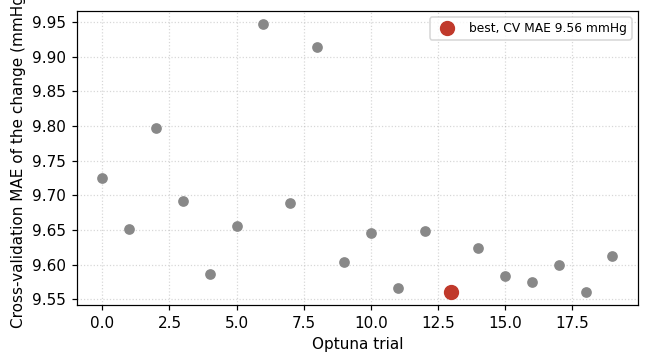

In [8]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
bp = json.load(open(f"{ABS}/optuna/XGB_baseline.best_params.json"))
if REFAZER_OPTUNA:
    HP, estudo = pesquisa_optuna(20)
else:
    HP = bp["best_params"]
    confere("a pesquisa guardada foi feita com as 27 características", bp["n_features"], 27)
    estudo = optuna.load_study(study_name="XGB_baseline", storage=f"sqlite:///{ABS}/optuna/XGB_baseline.db")
tentativas = sorted((t for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE), key=lambda t: t.number)[:20]
melhor = min(tentativas, key=lambda t: t.value)
if not REFAZER_OPTUNA:
    confere("tentativas consideradas", len(tentativas), bp["n_trials"])
    confere("a melhor das 20 tentativas é a guardada", melhor.params, HP)
display(pd.Series(HP, name="hiperparâmetros"))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot([t.number for t in tentativas], [t.value for t in tentativas], "o", color=CINZA)
ax.plot(melhor.number, melhor.value, "o", color=VERM, ms=9, label=f"best, CV MAE {melhor.value:.2f} mmHg")
ax.set_xlabel("Optuna trial"); ax.set_ylabel("Cross-validation MAE of the change (mmHg)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/tentativas.png", dpi=200); plt.show()

## 5. Modelo final e erro no conjunto de teste

O modelo é treinado em todo o conjunto de desenvolvimento e mede-se **uma só vez** no conjunto de teste. A previsão passa a pressão em três passos, iguais no treino e no servidor:

1. subtrai-se a média das 3 primeiras previsões da sessão, porque o modelo prevê desvios e o primeiro minuto fixa o zero;
2. suaviza-se a série com um filtro de Kalman só para a frente;
3. soma-se a pressão de calibração, `PA = sbp_calib + desvio`.

In [9]:
t0 = time.time()
SC, MODELO = treinar(HP, dev, FEATURES_V3)
PREV = pd.Series(MODELO.predict(SC.transform(teste[FEATURES_V3]), teste['age'].values), index=teste.index)
D_TESTE = reconstruir(teste, PREV)
M = metricas(D_TESTE)
print(f"treino e previsão em {time.time() - t0:.0f} s | MAE no teste {M['mae_sbp']:.3f} mmHg, {M['n']} blocos, "
      f"{M['n_sujeitos']} doentes")
ref = json.load(open(f"{REF}/experiencias/XGB_baseline/metricas.json"))
confere("MAE no teste (mmHg)", M['mae_sbp'], ref['mae_holdout'], tol=1e-6)
confere("blocos de teste previstos", M['n'], ref['n_holdout'])
guardadas = pd.read_csv(f"{REF}/experiencias/XGB_baseline/holdout_predicoes.csv")
confere("mesmos blocos que as previsões da tese", bool((D_TESTE[['session_id', 'bloco_id']].values
                                                        == guardadas[['session_id', 'bloco_id']].values).all()), True)
confere("diferença máxima face às previsões da tese (mmHg)",
        float(np.abs(D_TESTE.preds_final.values - guardadas.preds_final.values).max()), 0.0, tol=1e-6)

treino e previsão em 4 s | MAE no teste 12.070 mmHg, 50203 blocos, 40 doentes
  ok  MAE no teste (mmHg): 12.069689447499567
  ok  blocos de teste previstos: 50203
  ok  mesmos blocos que as previsões da tese: True
  ok  diferença máxima face às previsões da tese (mmHg): 5.684341886080802e-14


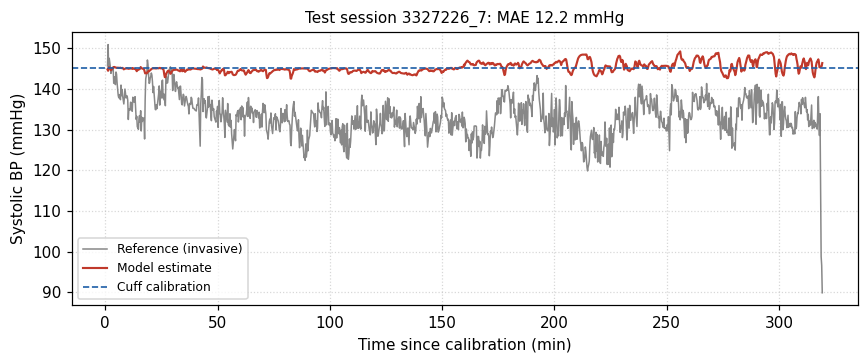

In [10]:
# uma sessão do conjunto de teste: a de pelo menos 2 h cujo MAE fica mais perto do global
por_sessao = D_TESTE.groupby('session_id').apply(lambda g: pd.Series(dict(n=len(g), mae=(g.preds_final - g.sbp_target).abs().mean())),
                                                 include_groups=False)
longa = por_sessao[por_sessao.n >= 2 * 3600 / BLOCO_SEG]
s = (longa.mae - M['mae_sbp']).abs().idxmin()
g = D_TESTE[D_TESTE.session_id == s]
t = g.tempo_desde_calib_seg / 60
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t, g.sbp_target, color=CINZA, lw=1, label="Reference (invasive)")
ax.plot(t, g.preds_final, color=VERM, lw=1.4, label="Model estimate")
ax.axhline(g.sbp_calib.iloc[0], color=AZUL, ls="--", lw=1.1, label="Cuff calibration")
ax.set_xlabel("Time since calibration (min)"); ax.set_ylabel("Systolic BP (mmHg)")
ax.set_title(f"Test session {s}: MAE {longa.loc[s, 'mae']:.1f} mmHg", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/serie_sessao.png", dpi=200); plt.show()

## 6. Validação cruzada no conjunto de desenvolvimento

É o MAE do desvio que a pesquisa do passo 4 otimizou, com 3 dobras por doente: cada bloco é previsto por um modelo que não viu o seu doente.

In [11]:
t0 = time.time()
MAE_CV, POR_DOBRA = validacao_cruzada(HP, dev, FEATURES_V3)
print(f"{time.time() - t0:.0f} s | MAE por dobra: {[round(x, 3) for x in POR_DOBRA]}")
confere("MAE de validação cruzada (mmHg)", MAE_CV, bp["mae_cv"], tol=1e-6)

11 s | MAE por dobra: [9.47, 10.082, 9.129]
  ok  MAE de validação cruzada (mmHg): 9.560547231268979


## 7. Suavização das previsões

O mesmo modelo, com três pós-processamentos: o filtro de Kalman (o adotado), uma média móvel exponencial (span de 5 blocos) e nenhuma suavização. Só muda o passo 2 do pós-processamento.

In [12]:
ref = {l['suavizacao']: l['mae_holdout'] for l in json.load(open(f"{REF}/tabelas/suavizacao.json"))['linhas']}
SUAV = {m: metricas(reconstruir(teste, PREV, m))['mae_sbp'] for m in ("kalman", "ewma", "none")}
display(pd.Series(SUAV, name="MAE no teste (mmHg)").round(3))
for m in SUAV:
    confere(f"MAE com suavização {m}", round(SUAV[m], 4), ref[m])

kalman    12.070
ewma      12.080
none      12.169
Name: MAE no teste (mmHg), dtype: float64

  ok  MAE com suavização kalman: 12.0697
  ok  MAE com suavização ewma: 12.0802
  ok  MAE com suavização none: 12.1694


## 8. Versões das características

As quatro versões incrementais da tese, todas com os **mesmos hiperparâmetros** (os do modelo de referência, a versão 3), para a diferença entre elas se dever só às características. A versão 4 junta o grupo nosológico do doente (cardíaco, respiratório), que vem de outro ficheiro.

In [13]:
diag = pd.read_csv(CSV_DIAGNOSTICO).rename(columns={"subject_id_str": "subject_id"})[["subject_id", "is_cardiac", "is_respiratory"]]
diag["subject_id"] = diag["subject_id"].astype(str)

def com_diagnostico(df):
    out = df.merge(diag, on="subject_id", how="left")
    assert len(out) == len(df)
    out[["is_cardiac", "is_respiratory"]] = out[["is_cardiac", "is_respiratory"]].fillna(0).astype(int)
    return out

ref = {l['versao']: l for l in json.load(open(f"{REF}/tabelas/versoes_features.json"))['linhas']}
VERS = {}
for v, feats in VERSOES.items():
    dv, tv = (com_diagnostico(dev), com_diagnostico(teste)) if v == "v4" else (dev, teste)
    VERS[v] = metricas(reconstruir(tv, ajustar_e_prever(HP, dv, tv, feats)))['mae_sbp']
    print(f"{v}: {len(feats)} características, MAE {VERS[v]:.3f} mmHg")
    confere(f"{v}: número de características", len(feats), ref[v]['n_features'])
    confere(f"{v}: MAE no teste", round(VERS[v], 4), ref[v]['mae_holdout'])

v1: 15 características, MAE 12.206 mmHg
  ok  v1: número de características: 15
  ok  v1: MAE no teste: 12.2058


v2: 21 características, MAE 11.927 mmHg
  ok  v2: número de características: 21
  ok  v2: MAE no teste: 11.9272


v3: 27 características, MAE 12.070 mmHg
  ok  v3: número de características: 27
  ok  v3: MAE no teste: 12.0697


v4: 29 características, MAE 12.092 mmHg
  ok  v4: número de características: 29
  ok  v4: MAE no teste: 12.092


## 9. Comparação com a âncora

A **âncora** é a estimativa mais simples possível, repetir o valor do manguito (`sbp_calib`) até à calibração seguinte. O ganho do modelo é o erro da âncora menos o do modelo (positivo quer dizer que o modelo erra menos), no teste todo e por faixa de tempo desde a calibração, com o intervalo de confiança a 95 % obtido sorteando **doentes** com reposição (1000 vezes).

  ok  ganho contra a âncora, todos: 0.1244174319033883
  ok  IC95 do ganho, todos: [-0.335027, 0.527724]
  ok  ganho contra a âncora, <5: -0.21261155901040343
  ok  IC95 do ganho, <5: [-0.375664, -0.06123]
  ok  ganho contra a âncora, 5-15: 0.04777779502433526
  ok  IC95 do ganho, 5-15: [-0.305754, 0.394632]
  ok  ganho contra a âncora, 15-30: 0.33136283646393677
  ok  IC95 do ganho, 15-30: [-0.170322, 0.788605]
  ok  ganho contra a âncora, 30-60: 0.22019632272922066
  ok  IC95 do ganho, 30-60: [-0.387859, 0.740196]
  ok  ganho contra a âncora, 60-120: 0.35100073338331533
  ok  IC95 do ganho, 60-120: [-0.240361, 0.787286]
  ok  ganho contra a âncora, >120: -0.04932331416360966
  ok  IC95 do ganho, >120: [-0.888738, 0.512834]


,n,ancora,modelo,ganho
faixa,,,,
<5,2201,3.15,3.36,-0.21
5-15,4967,6.40,6.35,0.05
15-30,5690,8.47,8.14,0.33
30-60,8688,11.59,11.37,0.22
60-120,10221,12.81,12.46,0.35
>120,18436,15.93,15.98,-0.05


  ok  erro por faixa de tempo desde a calibração (tab:ancora_horizonte): 3.552713678800501e-15


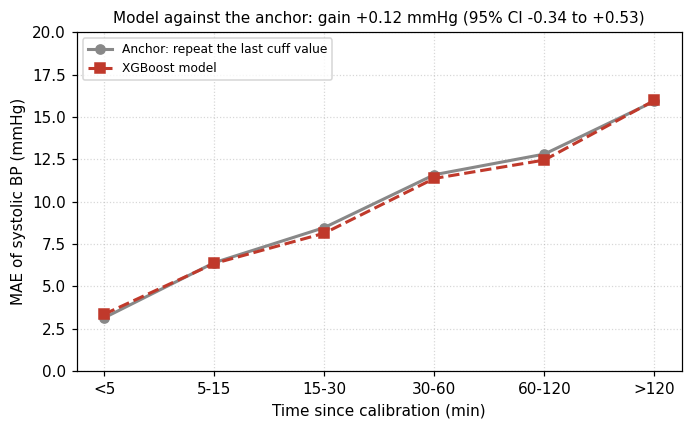

In [14]:
d = D_TESTE.copy()
d["err_modelo"] = (d.preds_final - d.sbp_target).abs()
d["err_ancora"] = (d.sbp_calib - d.sbp_target).abs()
d["ganho"] = d.err_ancora - d.err_modelo
d["idade_min"] = d.tempo_desde_calib_seg / 60.0
FAIXAS, ROT = [0, 5, 15, 30, 60, 120, 1e5], ["<5", "5-15", "15-30", "30-60", "60-120", ">120"]
d["faixa"] = pd.cut(d.idade_min, FAIXAS, labels=ROT)
rng = np.random.default_rng(SEMENTE)
por_suj = {s: g for s, g in d.groupby("subject_id")}

def ic(sel):
    base = {s: g[sel(g)] for s, g in por_suj.items()}
    base = {s: g for s, g in base.items() if len(g)}
    chaves = list(base)
    vals = [pd.concat([base[k] for k in rng.choice(chaves, len(chaves), replace=True)]).ganho.mean() for _ in range(1000)]
    sub = pd.concat(base.values())
    return float(sub.ganho.mean()), [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

GANHO = {"todos": ic(lambda g: np.ones(len(g), bool))}
for r in ROT:
    GANHO[r] = ic(lambda g, r=r: (g.faixa == r).values)
ref = json.load(open(f"{REF}/tabelas/ganho_contra_ancora.json"))
for k, (gm, ic95) in GANHO.items():
    confere(f"ganho contra a âncora, {k}", gm, ref[k]['ganho'], tol=1e-9)
    confere(f"IC95 do ganho, {k}", [round(x, 6) for x in ic95], [round(x, 6) for x in ref[k]['ic95']])

tab = (d.groupby('faixa', observed=True).agg(n=('err_modelo', 'size'), ancora=('err_ancora', 'mean'), modelo=('err_modelo', 'mean')))
tab['ganho'] = tab.ancora - tab.modelo
display(tab.round(2))
ref_tab = pd.read_csv(f"{REF}/tabelas/ancora_horizonte.csv").set_index('faixa_min')
confere("erro por faixa de tempo desde a calibração (tab:ancora_horizonte)",
        float(np.abs(tab[['ancora', 'modelo']].values - ref_tab[['ancora', 'modelo']].values).max()), 0.0, tol=1e-9)

fig, ax = plt.subplots(figsize=(6.4, 4))
x = np.arange(len(tab))
ax.plot(x, tab.ancora, 'o-', lw=2, color=CINZA, label='Anchor: repeat the last cuff value')
ax.plot(x, tab.modelo, 's--', lw=2, color=VERM, label='XGBoost model')
ax.set_xticks(x); ax.set_xticklabels(tab.index); ax.set_ylim(0, 20)
ax.set_xlabel('Time since calibration (min)'); ax.set_ylabel('MAE of systolic BP (mmHg)')
g0, (lo, hi) = GANHO['todos']
ax.set_title(f"Model against the anchor: gain {g0:+.2f} mmHg (95% CI {lo:+.2f} to {hi:+.2f})", fontsize=10)
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(f"{SAIDA}/ancora.png", dpi=200); plt.show()

## 10. Normas clínicas e análise de Bland-Altman

* **BHS**: percentagem de estimativas com erro até 5, 10 e 15 mmHg, por bloco e em média por doente, e o grau (A a D) correspondente.
* **AAMI / ISO 81060-2**: erro médio (enviesamento) até 5 mmHg e desvio padrão das diferenças até 8 mmHg.
* **Bland-Altman**: a diferença entre a estimativa e a referência em função da média das duas, com os limites de concordância (enviesamento ± 1,96 desvios padrão) e o declive da regressão, com o intervalo de confiança a 95 % por sorteio de doentes.

p5_janela       34.655299
p10_janela      55.004681
p15_janela      68.434157
grau_janela             D
p5_sujeito      38.167565
p10_sujeito     60.944589
p15_sujeito     74.435897
grau_sujeito            D
dtype: object

  ok  BHS, p5_janela: 34.65529948409458
  ok  BHS, p10_janela: 55.004680995159646
  ok  BHS, p15_janela: 68.43415732127562
  ok  BHS, grau_janela: D
  ok  BHS, p5_sujeito: 38.16756475392212
  ok  BHS, p10_sujeito: 60.944588788571174
  ok  BHS, p15_sujeito: 74.43589652882774
  ok  BHS, grau_sujeito: D


vies                                                  2.480859
sd_diferencas                                        16.381667
limite_inferior                                     -29.627209
limite_superior                                      34.588927
declive                                               0.117179
declive_ic95       [0.055365082286424845, 0.25624955578292946]
rmse_modelo                                          16.568293
rmse_ancora                                          16.823171
aami_vies_ok                                              True
aami_sd_ok                                               False
dtype: object

  ok  Bland-Altman, vies: 2.480859328568127
  ok  Bland-Altman, sd_diferencas: 16.381667308795084
  ok  Bland-Altman, limite_inferior: -29.62720859667024
  ok  Bland-Altman, limite_superior: 34.588927253806496
  ok  Bland-Altman, declive: 0.11717937002671856
  ok  Bland-Altman, declive_ic95: [0.055365, 0.25625]
  ok  Bland-Altman, rmse_modelo: 16.568293253873577
  ok  Bland-Altman, rmse_ancora: 16.823171470029504
  ok  Bland-Altman, aami_vies_ok: True
  ok  Bland-Altman, aami_sd_ok: False


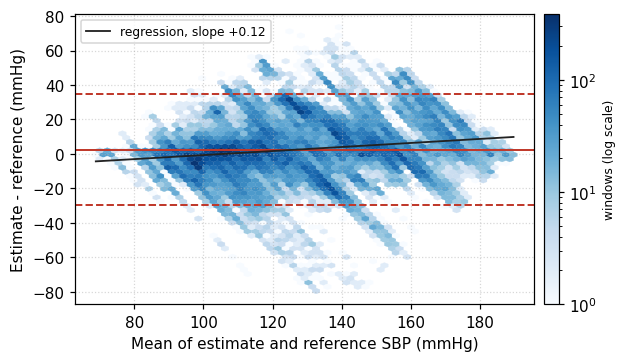

In [15]:
def grau_bhs(p5, p10, p15):
    for grau, (a, b, c) in (("A", (60, 85, 95)), ("B", (50, 75, 90)), ("C", (40, 65, 85))):
        if p5 >= a and p10 >= b and p15 >= c:
            return grau
    return "D"

e = (D_TESTE.preds_final - D_TESTE.sbp_target).abs()
por_janela = [100 * float((e <= t).mean()) for t in (5, 10, 15)]
por_sujeito = e.groupby(D_TESTE.subject_id).apply(lambda s: pd.Series([100 * (s <= t).mean() for t in (5, 10, 15)])).unstack().mean()
BHS = dict(p5_janela=por_janela[0], p10_janela=por_janela[1], p15_janela=por_janela[2], grau_janela=grau_bhs(*por_janela),
           p5_sujeito=float(por_sujeito.iloc[0]), p10_sujeito=float(por_sujeito.iloc[1]), p15_sujeito=float(por_sujeito.iloc[2]),
           grau_sujeito=grau_bhs(*por_sujeito.tolist()))
display(pd.Series(BHS))
ref = json.load(open(f"{REF}/tabelas/ancora_bhs.json"))["bhs"]
for k, v in BHS.items():
    confere(f"BHS, {k}", v, ref[k], tol=1e-9) if not isinstance(v, str) else confere(f"BHS, {k}", v, ref[k])

ref_v, est, anc = D_TESTE.sbp_target.values, D_TESTE.preds_final.values, D_TESTE.sbp_calib.values
dif, media = est - ref_v, (est + ref_v) / 2
declive = lambda x, y: float(np.polyfit(x, y, 1)[0])
rng = np.random.default_rng(SEMENTE)
sujeitos = D_TESTE.subject_id.values
ids = np.unique(sujeitos)
idx_por_suj = {s: np.where(sujeitos == s)[0] for s in ids}
boot = []
for _ in range(1000):
    amostra = np.concatenate([idx_por_suj[s] for s in rng.choice(ids, len(ids), replace=True)])
    boot.append(declive(media[amostra], dif[amostra]))
sd = float(dif.std(ddof=1))
BA = dict(vies=float(dif.mean()), sd_diferencas=sd, limite_inferior=float(dif.mean() - 1.96 * sd),
          limite_superior=float(dif.mean() + 1.96 * sd), declive=declive(media, dif),
          declive_ic95=[float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))],
          rmse_modelo=float(np.sqrt(np.mean(dif ** 2))), rmse_ancora=float(np.sqrt(np.mean((anc - ref_v) ** 2))),
          aami_vies_ok=bool(abs(dif.mean()) <= 5), aami_sd_ok=bool(sd <= 8))
display(pd.Series(BA))
ref = json.load(open(f"{REF}/tabelas/bland_altman.json"))
for k, v in BA.items():
    if isinstance(v, list):
        confere(f"Bland-Altman, {k}", [round(x, 6) for x in v], [round(x, 6) for x in ref[k]])
    elif isinstance(v, bool):
        confere(f"Bland-Altman, {k}", v, ref[k])
    else:
        confere(f"Bland-Altman, {k}", v, ref[k], tol=1e-9)

fig, ax = plt.subplots(figsize=(5.8, 3.4))
hb = ax.hexbin(media, dif, gridsize=55, bins="log", cmap="Blues", mincnt=1, linewidths=0.2)
for y, ls in ((BA['vies'], "-"), (BA['limite_superior'], "--"), (BA['limite_inferior'], "--")):
    ax.axhline(y, color=VERM, ls=ls, lw=1.3)
xx = np.array([media.min(), media.max()])
ax.plot(xx, np.polyval(np.polyfit(media, dif, 1), xx), color="#222222", lw=1.2, label=f"regression, slope {BA['declive']:+.2f}")
ax.set_xlabel("Mean of estimate and reference SBP (mmHg)"); ax.set_ylabel("Estimate - reference (mmHg)")
ax.legend(loc="upper left", fontsize=8); fig.colorbar(hb, ax=ax, pad=0.02, fraction=0.045).set_label("windows (log scale)", fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/bland_altman.png", dpi=200); plt.show()

## 11. Contributo das características

Valores de Shapley do modelo final, numa amostra fixa de 3000 blocos do conjunto de teste, calculados em cada um dos dois boosters (menos e mais de 60 anos). A importância de cada característica é a média do valor absoluto.

alpha_womersley_global_z    1.265
area_mean_global_z          0.845
pat_calib_stability         0.564
pat_lag1                    0.549
pat_mean_z                  0.527
age                         0.454
tempo_desde_calib_seg       0.450
hr_mean_z                   0.393
qrs_area_global_z           0.323
pat_variance_ratio          0.297
dtype: float64

  ok  SHAP: mesma ordem das características: 27 elementos, iguais
  ok  SHAP: diferença máxima face à da tese: 9.063930161978817e-17


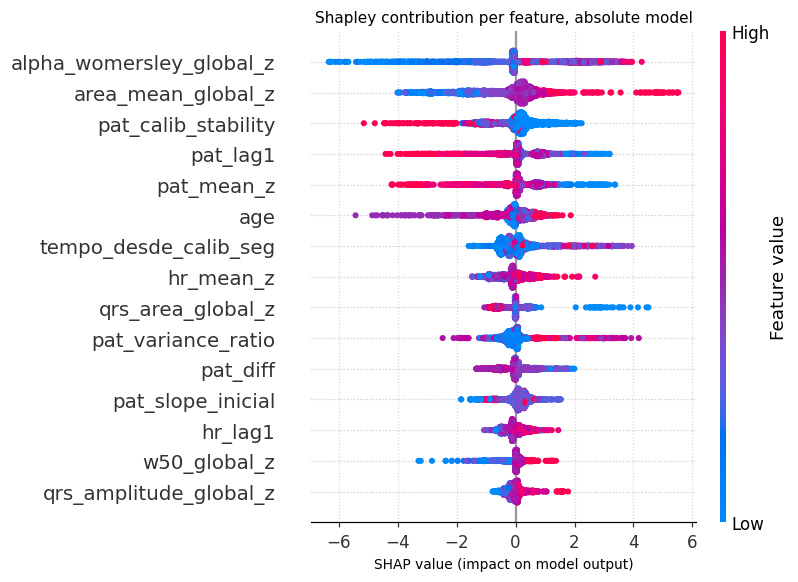

In [16]:
import shap
N_AMOSTRA = 3000
Xt = SC.transform(teste[FEATURES_V3])
idx = np.sort(np.random.default_rng(SEMENTE).choice(len(teste), size=min(N_AMOSTRA, len(teste)), replace=False))
Xa, idades = Xt[idx], teste['age'].values[idx]
valores = np.zeros_like(Xa)
for mascara, booster in ((idades < IDADE_CORTE, MODELO.modelo_jovem), (idades >= IDADE_CORTE, MODELO.modelo_senior)):
    if mascara.any() and booster is not None:
        valores[mascara] = shap.TreeExplainer(booster).shap_values(Xa[mascara])
IMP = pd.Series(np.abs(valores).mean(axis=0), index=FEATURES_V3).sort_values(ascending=False)
display(IMP.head(10).round(3))
ref = pd.read_csv(f"{REF}/tabelas/shap_importancia.csv").set_index("feature")["shap_abs_medio"]
confere("SHAP: mesma ordem das características", list(IMP.index), list(ref.index))
confere("SHAP: diferença máxima face à da tese", float((IMP - ref.reindex(IMP.index)).abs().max()), 0.0, tol=1e-6)

shap.summary_plot(valores, Xa, feature_names=FEATURES_V3, show=False, max_display=15, plot_size=(7.4, 5.4))
plt.title("Shapley contribution per feature, absolute model", fontsize=10)
plt.xlabel("SHAP value (impact on model output)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{SAIDA}/shap.png", dpi=200, bbox_inches="tight"); plt.show()

## 12. Exportação do modelo

O servidor carrega um pacote (`modelo_sbp.joblib`) com os dois boosters, a média e o desvio do escalonamento, a lista das características pela ordem do treino, os parâmetros do filtro de Kalman e o número de previsões iniciais que fixam o zero da sessão. Aqui exporta-se o modelo do passo 5 nesse formato, para a pasta de saída, e confirma-se que, lido de volta pelo caminho do servidor, dá as mesmas previsões.

O pacote instalado no servidor é o que este notebook exporta. Que o servidor calcula as mesmas características e as mesmas previsões que o treino verifica-se em `modelo_e_experiencias/19_verificar_servidor.py`.

In [17]:
import datetime
pacote = {"formato": 1, "alvo": ALVO, "features": list(FEATURES_V3),
          "scaler_mean": SC.mean_, "scaler_scale": SC.scale_, "idade_corte": IDADE_CORTE,
          "booster_young": bytes(MODELO.modelo_jovem.save_raw()), "booster_senior": bytes(MODELO.modelo_senior.save_raw()),
          "suavizacao": {"metodo": "kalman", "r": 1.0, **KALMAN}, "ancora_offset_blocos": 3,
          "meta": {"treinado_em": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
                   "variante": "baseline, ancoras CAUSAIS por SESSAO, 27 caracteristicas",
                   "n_doentes_dev": int(dev.subject_id.nunique()), "n_blocos_dev": int(len(dev)),
                   "hiperparametros": HP, "mae_dev_cv": round(MAE_CV, 4), "mae_holdout": round(M['mae_sbp'], 4)}}
joblib.dump(pacote, f"{SAIDA}/modelo_sbp.joblib")
servidor = joblib.load(SERVIDOR)
confere("pacote com as mesmas chaves do instalado no servidor", sorted(pacote), sorted(servidor))
print(f"servidor: {len(servidor['features'])} características, treinado em {servidor['meta'].get('treinado_em')}")

def prever_pacote(pac):
    X = (teste[pac["features"]].values - pac["scaler_mean"]) / pac["scaler_scale"]
    p = np.zeros(len(X))
    for nome, mascara in (("booster_young", teste.age.values < pac["idade_corte"]), ("booster_senior", teste.age.values >= pac["idade_corte"])):
        b = xgb.Booster(); b.load_model(bytearray(pac[nome]))
        p[mascara] = b.predict(xgb.DMatrix(X[mascara]))
    return p

confere("pacote lido de volta: diferença máxima das previsões no teste",
        float(np.abs(prever_pacote(joblib.load(f"{SAIDA}/modelo_sbp.joblib")) - PREV.values).max()), 0.0, tol=1e-5)
confere("pacote instalado no servidor: diferença máxima das previsões no teste",
        float(np.abs(prever_pacote(servidor) - PREV.values).max()), 0.0, tol=1e-5)

  ok  pacote com as mesmas chaves do instalado no servidor: ['alvo', 'ancora_offset_blocos', 'booster_senior', 'booster_young', 'features', 'formato', 'idade_corte', 'meta', 'scaler_mean', 'scaler_scale', 'suavizacao']
servidor: 27 características, treinado em 2026-10-14 05:18
  ok  pacote lido de volta: diferença máxima das previsões no teste: 0.0
  ok  pacote instalado no servidor: diferença máxima das previsões no teste: 0.0


## Resumo das verificações

In [18]:
v = pd.DataFrame(VERIFICACOES, columns=["verificação", "obtido", "na tese", "igual"])
print(f"{int(v.igual.sum())} de {len(v)} verificações iguais aos resultados da tese")
display(v)

74 de 74 verificações iguais aos resultados da tese


,verificação,obtido,na tese,igual
0,versão do XGBoost (a dos resultados da tese),3.2.0,3.2.0,True
1,versão do scikit-learn (a dos resultados da tese),1.8.0,1.8.0,True
2,demonstração: mesmas janelas aceites,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",True
3,demonstração: diferença máxima nas característ...,0.000007,0.0,True
4,mesmo número de blocos,371870,371870,True
...,...,...,...,...
69,SHAP: mesma ordem das características,"[alpha_womersley_global_z, area_mean_global_z,...","[alpha_womersley_global_z, area_mean_global_z,...",True
70,SHAP: diferença máxima face à da tese,0.0,0.0,True
71,pacote com as mesmas chaves do instalado no se...,"[alvo, ancora_offset_blocos, booster_senior, b...","[alvo, ancora_offset_blocos, booster_senior, b...",True
72,pacote lido de volta: diferença máxima das pre...,0.0,0.0,True


## 13. O que fica fora deste notebook

Este notebook segue o caminho do modelo de referência. As análises à volta dele estão em scripts próprios, que a tabela seguinte indica.

| Análise | Onde está | Na tese |
|---|---|---|
| Redes (BiLSTM, BiTCN) e híbridos, com três sementes | `2_estimacao_absoluta/modelo_e_experiencias/01_correr_experiencia.py`, `02_sementes_bootstrap.py`, `03_tabelas_modelos.py` | Cap. 6, seleção do modelo |
| Variantes de extração (NeuroKit2, FFT, covariáveis clínicas) | `modelo_e_experiencias/01_correr_experiencia.py`, `06_tabela_variantes.py`, `10_janelas_emparelhadas.py` | Cap. 6 e anexos |
| Porque é que o erro não diminui (planalto, autocorrelação do resíduo, correlação PAT-PAS) | `modelo_e_experiencias/03_tabelas_modelos.py`, `09_analise_deriva.py`, `16_direcao_variacao.py` | Cap. 6 |
| Custo da normalização causal | `modelo_e_experiencias/08_custo_normalizacao_causal.py` | Cap. 6 |
| Reprodutibilidade das redes e dos híbridos | `modelo_e_experiencias/14_reprodutibilidade.py` | anexos |
| Estimação no servidor | `server/worker_absoluto.py` | Cap. 4 e Cap. 7 |
| Deteção de tendência | notebooks `02_tendencia_classificador.ipynb` e `03_tendencia_regressao_quantilica.ipynb` | Cap. 6 |